<a href="https://colab.research.google.com/github/sejal-oli7/Elevvo-Machine-Learning-Internship/blob/main/predictive_maintenance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (confusion_matrix, precision_recall_curve, average_precision_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)
from xgboost import XGBClassifier
RANDOM_STATE = 42
sns.set_style("whitegrid")

In [6]:
CSV_PATH = "/content/predictive_maintenance_datasets.csv"

df = pd.read_csv(CSV_PATH)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [7]:
df.columns = df.columns.str.strip()
rename_map = {
    "Air temperature [K]": "air_temp",
    "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm",
    "Torque [Nm]": "torque",
    "Tool wear [min]": "tool_wear",
    "Machine failure": "failure",
    "Target": "failure",            # name used in another Kaggle version
    "Type": "type",
    "Failure Type": "failure_type", # name used in another Kaggle version
}
df = df.rename(columns=rename_map)
df = df.drop(columns=["UDI", "UID", "Product ID"], errors="ignore")

mode_names = {"TWF": "Tool Wear Failure", "HDF": "Heat Dissipation Failure",
              "PWF": "Power Failure", "OSF": "Overstrain Failure", "RNF": "Random Failures"}

if "failure_type" not in df.columns:
    flags = [c for c in mode_names if c in df.columns]
    def get_type(row):
        if row["failure"] == 0:
            return "No Failure"
        active = [mode_names[c] for c in flags if row[c] == 1]
        if len(active) == 1:
            return active[0]
        return "Multiple Failures" if len(active) > 1 else "Unspecified Failure"
    df["failure_type"] = df.apply(get_type, axis=1)

print(df.columns.tolist())
df.info()

['type', 'air_temp', 'process_temp', 'rpm', 'torque', 'tool_wear', 'failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'failure_type']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   type          10000 non-null  object 
 1   air_temp      10000 non-null  float64
 2   process_temp  10000 non-null  float64
 3   rpm           10000 non-null  int64  
 4   torque        10000 non-null  float64
 5   tool_wear     10000 non-null  int64  
 6   failure       10000 non-null  int64  
 7   TWF           10000 non-null  int64  
 8   HDF           10000 non-null  int64  
 9   PWF           10000 non-null  int64  
 10  OSF           10000 non-null  int64  
 11  RNF           10000 non-null  int64  
 12  failure_type  10000 non-null  object 
dtypes: float64(3), int64(8), object(2)
memory usage: 1015.8+ KB


In [8]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df[["air_temp", "process_temp", "rpm", "torque", "tool_wear"]].describe()

Missing values:
 type            0
air_temp        0
process_temp    0
rpm             0
torque          0
tool_wear       0
failure         0
TWF             0
HDF             0
PWF             0
OSF             0
RNF             0
failure_type    0
dtype: int64

Duplicate rows: 0


,air_temp,process_temp,rpm,torque,tool_wear
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000
std,2.000259,1.483734,179.284096,9.968934,63.654147
min,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000
max,304.500000,313.800000,2886.000000,76.600000,253.000000


failure
0    9661
1     339
Name: count, dtype: int64
Failure rate: 3.39 %


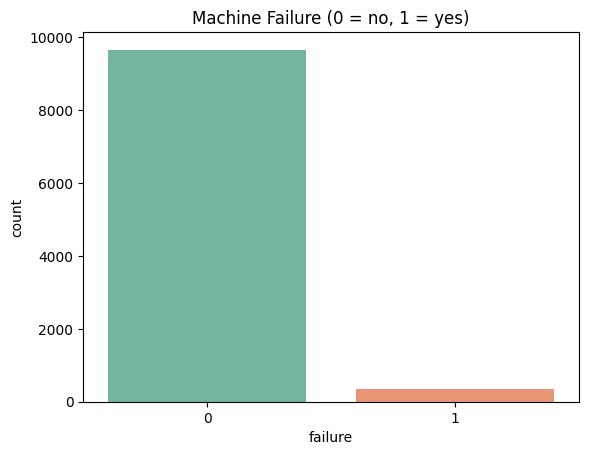

In [9]:
rate = df["failure"].mean() * 100
print(df["failure"].value_counts())
print("Failure rate: %.2f %%" % rate)

sns.countplot(data=df, x="failure", hue="failure", palette="Set2", legend=False)
plt.title("Machine Failure (0 = no, 1 = yes)")
plt.show()

In [10]:
# Which failure types occur?
df.loc[df["failure"] == 1, "failure_type"].value_counts()

,count
failure_type,
Heat Dissipation Failure,106
Power Failure,80
Overstrain Failure,78
Tool Wear Failure,42
Multiple Failures,24
Unspecified Failure,9


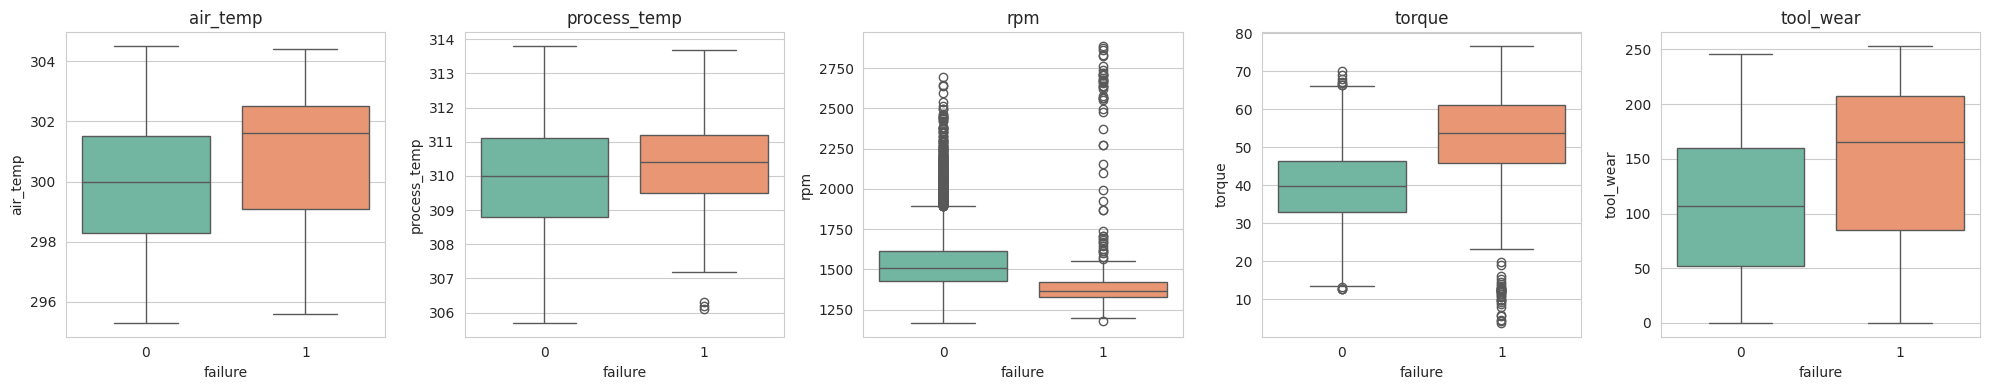

In [16]:
sensors = ["air_temp", "process_temp", "rpm", "torque", "tool_wear"]
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, sensors):
    sns.boxplot(data=df, x="failure", y=col, hue="failure", ax=ax, palette="Set2", legend=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

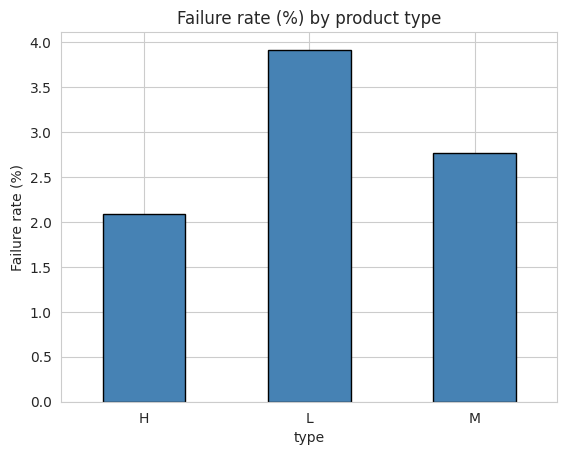

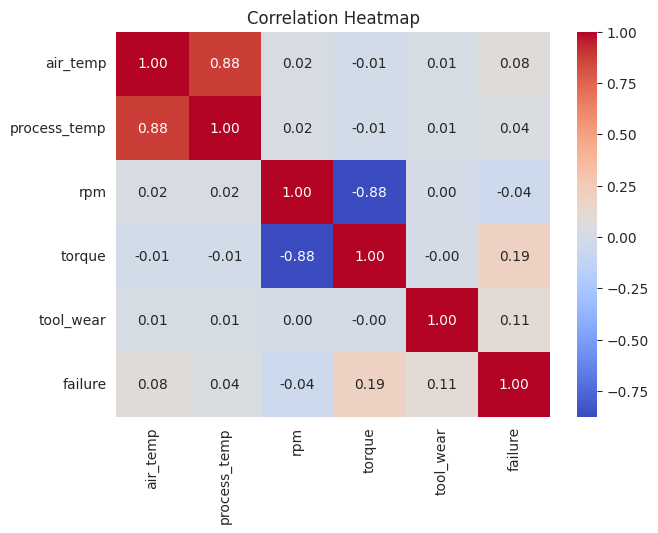

In [17]:
# Failure rate by product quality type (L / M / H)
(df.groupby("type")["failure"].mean() * 100).plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Failure rate (%) by product type")
plt.ylabel("Failure rate (%)")
plt.xticks(rotation=0)
plt.show()

plt.figure(figsize=(7, 5))
sns.heatmap(df[sensors + ["failure"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [18]:
df["temp_diff"] = df["process_temp"] - df["air_temp"]
df["power_w"] = df["torque"] * df["rpm"] * 2 * np.pi / 60
df["wear_torque"] = df["tool_wear"] * df["torque"]

num_cols = sensors + ["temp_diff", "power_w", "wear_torque"]
cat_cols = ["type"]
X = df[num_cols + cat_cols]
y = df["failure"]

df[["temp_diff", "power_w", "wear_torque"]].describe().round(1)

,temp_diff,power_w,wear_torque
count,10000.0,10000.0,10000.0
mean,10.0,6279.7,4314.7
std,1.0,1067.4,2826.6
min,7.6,1148.4,0.0
25%,9.3,5561.2,1963.6
50%,9.8,6271.0,4013.0
75%,11.0,7003.0,6279.0
max,12.1,10469.9,16497.0


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Failures  train: %d | test: %d" % (y_train.sum(), y_test.sum()))

Train: (8000, 9) | Test: (2000, 9)
Failures  train: 271 | test: 68


In [20]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])

spw = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": Pipeline([("prep", make_preprocessor()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([("prep", make_preprocessor()),
        ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                       min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1))]),
    "XGBoost": Pipeline([("prep", make_preprocessor()),
        ("clf", XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                              scale_pos_weight=spw, eval_metric="logloss",
                              random_state=RANDOM_STATE, n_jobs=-1))]),
}

for name, model in models.items():
    model.fit(X_train, y_train)
print("All models trained. scale_pos_weight = %.1f" % spw)

All models trained. scale_pos_weight = 28.5


In [21]:
MIN_RECALL = 0.70   # business rule: still catch at least 70 % of real failures

def metrics_at(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "Threshold": round(float(thr), 3),
        "Precision": tp / (tp + fp) if (tp + fp) > 0 else np.nan,
        "Recall": tp / (tp + fn) if (tp + fn) > 0 else np.nan,
        "FDR": fp / (tp + fp) if (tp + fp) > 0 else np.nan,
        "F1": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0.0,
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
    }

def pick_threshold(y_true, proba, min_recall=MIN_RECALL):
    prec, rec, thr = precision_recall_curve(y_true, proba)
    prec, rec = prec[:-1], rec[:-1]
    fdr = 1 - prec
    ok = np.where(rec >= min_recall)[0]        # thresholds that still catch enough failures
    score = fdr[ok] - 1e-6 * rec[ok]           # lowest FDR, ties broken by higher recall
    return float(thr[ok[np.argmin(score)]])

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

oof_proba, tuned_thr, oof_rows = {}, {}, []
for name, model in models.items():
    p = cross_val_predict(clone(model), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    oof_proba[name] = p
    tuned_thr[name] = pick_threshold(y_train, p)
    m = metrics_at(y_train, p, tuned_thr[name])
    oof_rows.append({"Model": name, "Threshold": m["Threshold"], "CV Recall": m["Recall"],
                     "CV FDR": m["FDR"], "CV Precision": m["Precision"]})

cv_table = pd.DataFrame(oof_rows).set_index("Model").round(3)
best_name = cv_table["CV FDR"].idxmin()
print("Best model (lowest cross-validated FDR with recall >= %.0f%%): %s" % (MIN_RECALL * 100, best_name))
cv_table

Best model (lowest cross-validated FDR with recall >= 70%): Random Forest


,Threshold,CV Recall,CV FDR,CV Precision
Model,,,,
Logistic Regression,0.703,0.701,0.745,0.255
Random Forest,0.613,0.723,0.020,0.980
XGBoost,0.969,0.708,0.054,0.946


In [24]:
test_proba = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}

rows = []
for name in models:
    d = metrics_at(y_test, test_proba[name], 0.5)
    t = metrics_at(y_test, test_proba[name], tuned_thr[name])
    rows.append({"Model": name, "Setting": "Default (0.5)", **d,
                 "PR-AUC": average_precision_score(y_test, test_proba[name])})
    rows.append({"Model": name, "Setting": "Tuned for low FDR", **t,
                 "PR-AUC": average_precision_score(y_test, test_proba[name])})

results = pd.DataFrame(rows).set_index(["Model", "Setting"]).round(3)
results[["Threshold", "Precision", "Recall", "FDR", "F1", "TP", "FP", "FN", "PR-AUC"]]

Threshold  Precision  Recall    FDR  \
Model               Setting                                                  
Logistic Regression Default (0.5)          0.500      0.179   0.882  0.821   
                    Tuned for low FDR      0.703      0.292   0.794  0.708   
Random Forest       Default (0.5)          0.500      0.947   0.794  0.053   
                    Tuned for low FDR      0.613      0.961   0.721  0.039   
XGBoost             Default (0.5)          0.500      0.718   0.824  0.282   
                    Tuned for low FDR      0.969      0.939   0.676  0.061   

                                          F1  TP   FP  FN  PR-AUC  
Model               Setting                                        
Logistic Regression Default (0.5)      0.298  60  275   8   0.430  
                    Tuned for low FDR  0.427  54  131  14   0.430  
Random Forest       Default (0.5)      0.864  54    3  14   0.875  
                    Tuned for low FDR  0.824  49    2  19   0.875  
XGBoost             Default (0.5)      0.767  56   22  12   0.888  
                    Tuned for low FDR  0.786  46    3  22   0.888

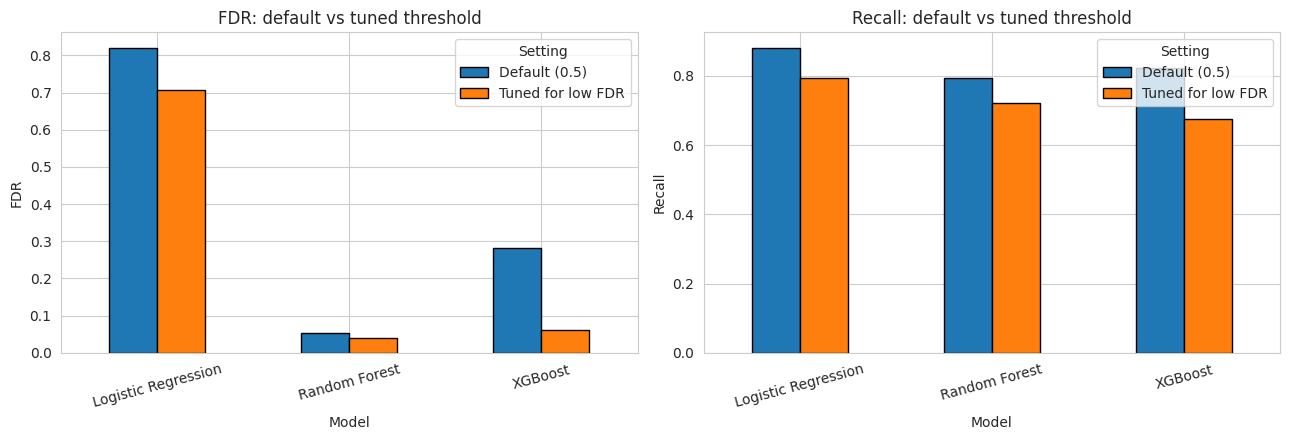

In [25]:
# Fewer false alarms: default vs tuned threshold
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ["FDR", "Recall"]):
    pivot = results[metric].unstack("Setting")[["Default (0.5)", "Tuned for low FDR"]]
    pivot.plot(kind="bar", ax=ax, edgecolor="black")
    ax.set_title(f"{metric}: default vs tuned threshold")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

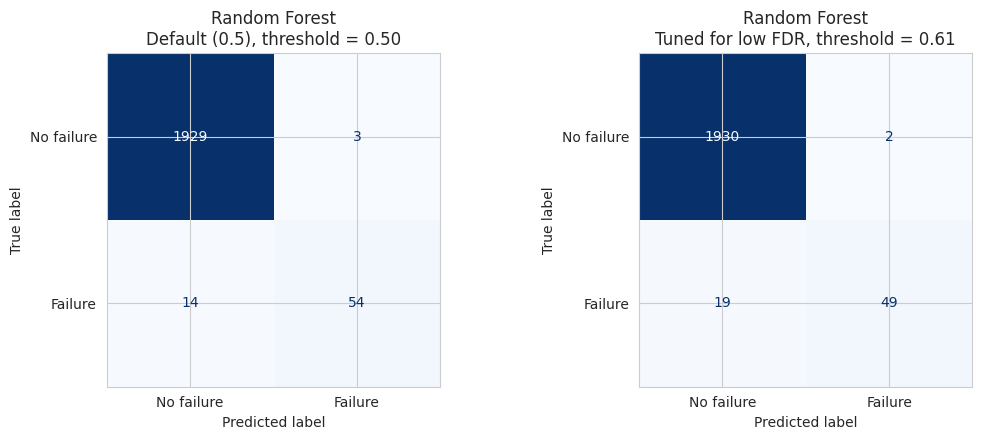

In [26]:
# Confusion matrices for the best model
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (label, thr) in zip(axes, [("Default (0.5)", 0.5), ("Tuned for low FDR", tuned_thr[best_name])]):
    pred = (test_proba[best_name] >= thr).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No failure", "Failure"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{best_name}\n{label}, threshold = {thr:.2f}")
plt.tight_layout()
plt.show()

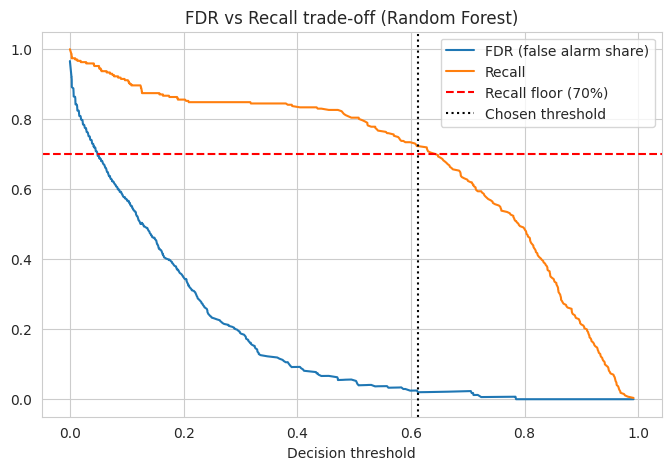

In [27]:
# Precision, recall and FDR as the threshold moves (cross-validated, best model)
prec, rec, thr = precision_recall_curve(y_train, oof_proba[best_name])
plt.figure(figsize=(8, 5))
plt.plot(thr, (1 - prec[:-1]), label="FDR (false alarm share)")
plt.plot(thr, rec[:-1], label="Recall")
plt.axhline(MIN_RECALL, color="red", linestyle="--", label=f"Recall floor ({MIN_RECALL:.0%})")
plt.axvline(tuned_thr[best_name], color="black", linestyle=":", label="Chosen threshold")
plt.xlabel("Decision threshold")
plt.title(f"FDR vs Recall trade-off ({best_name})")
plt.legend()
plt.show()

In [28]:
COST_FALSE_ALARM = 5_000     # assumed cost of one unnecessary production stop
COST_MISSED_FAIL = 20_000    # assumed cost of one missed failure

cost = results[["FP", "FN"]].copy()
cost["Total cost"] = cost["FP"] * COST_FALSE_ALARM + cost["FN"] * COST_MISSED_FAIL
cost

FP  FN  Total cost
Model               Setting                               
Logistic Regression Default (0.5)      275   8     1535000
                    Tuned for low FDR  131  14      935000
Random Forest       Default (0.5)        3  14      295000
                    Tuned for low FDR    2  19      390000
XGBoost             Default (0.5)       22  12      350000
                    Tuned for low FDR    3  22      455000

In [29]:
iso_cols = sensors
scaler = StandardScaler().fit(X_train[iso_cols])
iso = IsolationForest(n_estimators=300, contamination=float(y_train.mean()),
                      random_state=RANDOM_STATE).fit(scaler.transform(X_train[iso_cols]))

iso_pred = (iso.predict(scaler.transform(X_test[iso_cols])) == -1).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, iso_pred, labels=[0, 1]).ravel()
print("Isolation Forest on the test set")
print("Precision: %.3f | Recall: %.3f | FDR: %.3f | TP: %d | FP: %d | FN: %d" % (
      tp / max(tp + fp, 1), tp / max(tp + fn, 1), fp / max(tp + fp, 1), tp, fp, fn))

Isolation Forest on the test set
Precision: 0.123 | Recall: 0.103 | FDR: 0.877 | TP: 7 | FP: 50 | FN: 61


In [30]:
type_counts = df["failure_type"].value_counts()
rare = type_counts[type_counts < 10].index
y_type = df["failure_type"].where(~df["failure_type"].isin(rare), "Other (rare)")
print(y_type.value_counts())

Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    X, y_type, test_size=0.2, stratify=y_type, random_state=RANDOM_STATE)

type_model = Pipeline([("prep", make_preprocessor()),
    ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                   min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1))])
type_model.fit(Xt_train, yt_train)
yt_pred = type_model.predict(Xt_test)

print(classification_report(yt_test, yt_pred, digits=3, zero_division=0))

failure_type
No Failure                  9661
Heat Dissipation Failure     106
Power Failure                 80
Overstrain Failure            78
Tool Wear Failure             42
Multiple Failures             24
Other (rare)                   9
Name: count, dtype: int64
                          precision    recall  f1-score   support

Heat Dissipation Failure      0.955     1.000     0.977        21
       Multiple Failures      0.800     0.800     0.800         5
              No Failure      0.995     0.999     0.997      1932
            Other (rare)      0.000     0.000     0.000         2
      Overstrain Failure      0.941     1.000     0.970        16
           Power Failure      1.000     0.938     0.968        16
       Tool Wear Failure      0.000     0.000     0.000         8

                accuracy                          0.994      2000
               macro avg      0.670     0.677     0.673      2000
            weighted avg      0.989     0.994     0.991      2000



,Precision,Recall,F1,FDR,Support
Heat Dissipation Failure,0.955,1.000,0.977,0.045,21
Multiple Failures,0.800,0.800,0.800,0.200,5
No Failure,0.995,0.999,0.997,0.005,1932
Other (rare),0.000,0.000,0.000,1.000,2
Overstrain Failure,0.941,1.000,0.970,0.059,16
Power Failure,1.000,0.938,0.968,0.000,16
Tool Wear Failure,0.000,0.000,0.000,1.000,8


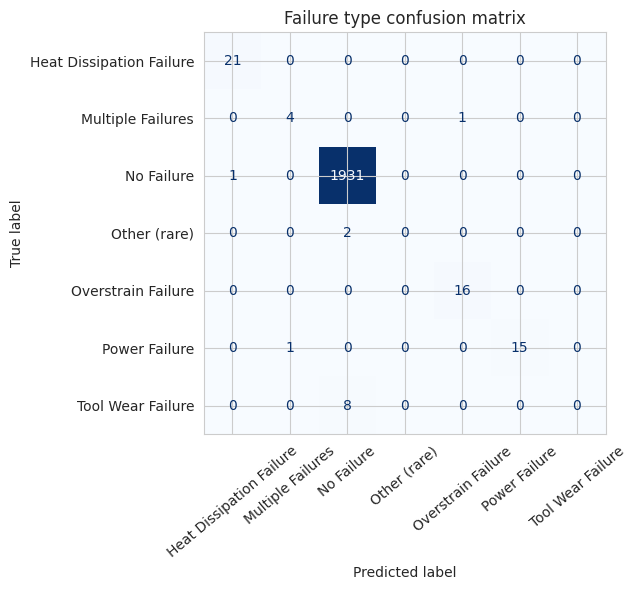

In [31]:
labels = sorted(y_type.unique())
p, r, f, s = precision_recall_fscore_support(yt_test, yt_pred, labels=labels, zero_division=0)
type_table = pd.DataFrame({"Precision": p, "Recall": r, "F1": f, "FDR": 1 - p, "Support": s}, index=labels).round(3)
display(type_table)

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(yt_test, yt_pred, labels=labels, cmap="Blues",
                                        xticks_rotation=40, ax=ax, colorbar=False)
ax.set_title("Failure type confusion matrix")
plt.tight_layout()
plt.show()

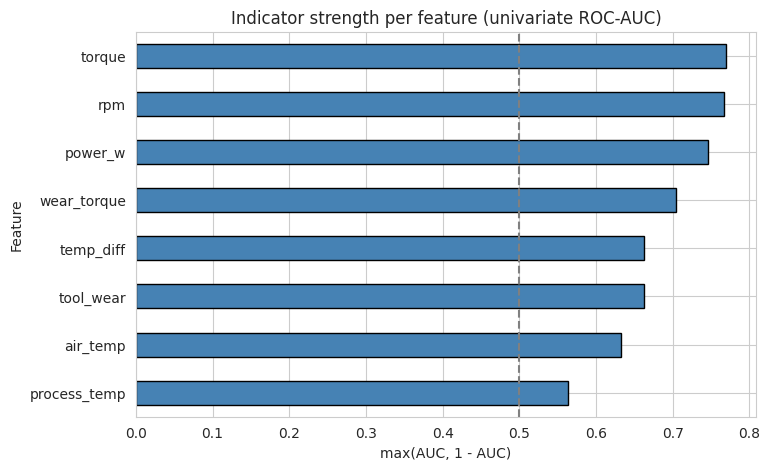

,AUC,Strength,Correlation
Feature,,,
torque,0.770,0.770,0.191
rpm,0.233,0.767,-0.044
power_w,0.746,0.746,0.176
wear_torque,0.704,0.704,0.190
temp_diff,0.338,0.662,-0.112
tool_wear,0.662,0.662,0.105
air_temp,0.633,0.633,0.083
process_temp,0.564,0.564,0.036


In [32]:
rows = []
for col in num_cols:
    auc = roc_auc_score(df["failure"], df[col])
    rows.append({"Feature": col, "AUC": auc, "Strength": max(auc, 1 - auc),
                 "Correlation": df[col].corr(df["failure"])})
ind = pd.DataFrame(rows).set_index("Feature").sort_values("Strength", ascending=False).round(3)

ind["Strength"][::-1].plot(kind="barh", color="steelblue", edgecolor="black", figsize=(8, 5))
plt.axvline(0.5, color="grey", linestyle="--")
plt.title("Indicator strength per feature (univariate ROC-AUC)")
plt.xlabel("max(AUC, 1 - AUC)")
plt.show()
ind

In [33]:
t = metrics_at(y_test, test_proba[best_name], tuned_thr[best_name])
d = metrics_at(y_test, test_proba[best_name], 0.5)
print("Best model (chosen with cross-validation):", best_name)
print("\nDefault threshold 0.5   -> Precision %.3f | Recall %.3f | FDR %.3f | false alarms (FP): %d" % (
      d["Precision"], d["Recall"], d["FDR"], d["FP"]))
print("Tuned threshold %.3f -> Precision %.3f | Recall %.3f | FDR %.3f | false alarms (FP): %d" % (
      t["Threshold"], t["Precision"], t["Recall"], t["FDR"], t["FP"]))
print("\nStrongest single indicator:", ind.index[0])

Best model (chosen with cross-validation): Random Forest

Default threshold 0.5   -> Precision 0.947 | Recall 0.794 | FDR 0.053 | false alarms (FP): 3
Tuned threshold 0.613 -> Precision 0.961 | Recall 0.721 | FDR 0.039 | false alarms (FP): 2

Strongest single indicator: torque


## Conclusion

- The dataset has 10,000 machine records with a 3.39% failure rate (339 failures) and no missing values.
- Random Forest had the lowest cross-validated False Discovery Rate (0.020) while catching at least 70% of failures, so it was selected as the best model.
- On the test set (68 failures), the tuned Random Forest reached precision 0.961, recall 0.721 and an FDR of 0.039, with only 2 false alarms.
- Threshold tuning helped XGBoost the most: false alarms dropped from 22 to 3 and FDR from 0.282 to 0.061, at the cost of recall (0.824 to 0.676).
- For Random Forest, tuning removed only 1 false alarm (3 to 2) but caused 5 more missed failures (14 to 19). With the assumed costs (5,000 per false alarm, 20,000 per missed failure), the default threshold was actually cheaper. The best threshold depends on the real cost of each error.
- Logistic Regression was not suitable: its FDR stayed at 0.708 even after tuning. Isolation Forest, which does not use labels, also performed poorly (FDR 0.877).
- The failure type model separated Heat Dissipation, Power and Overstrain failures well (F1 about 0.97). It could not detect Tool Wear failures (0 of 8 test cases), so the overall accuracy of 0.994 hides a macro F1 of only 0.673.
- Torque is the sensor most associated with failure (AUC 0.770), followed by rotational speed (0.767). This shows association only, because the dataset has no timestamps.
- The Time-to-Failure bonus was not attempted because the dataset has no time-to-failure column.